In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
df = sns.load_dataset("titanic")

In [2]:
d = df[["age", "fare", "pclass", "sex", "survived"]].dropna(subset=["age"])
X = d[["age", "fare", "pclass", "sex"]]
y = d["survived"]
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (571, 4) | Test: (143, 4)


In [3]:
prop = pd.DataFrame({
"train": y_train.value_counts(normalize=True).sort_index(),
"test": y_test.value_counts(normalize=True).sort_index()
})
print(prop.round(3))

          train   test
survived              
0         0.594  0.594
1         0.406  0.406


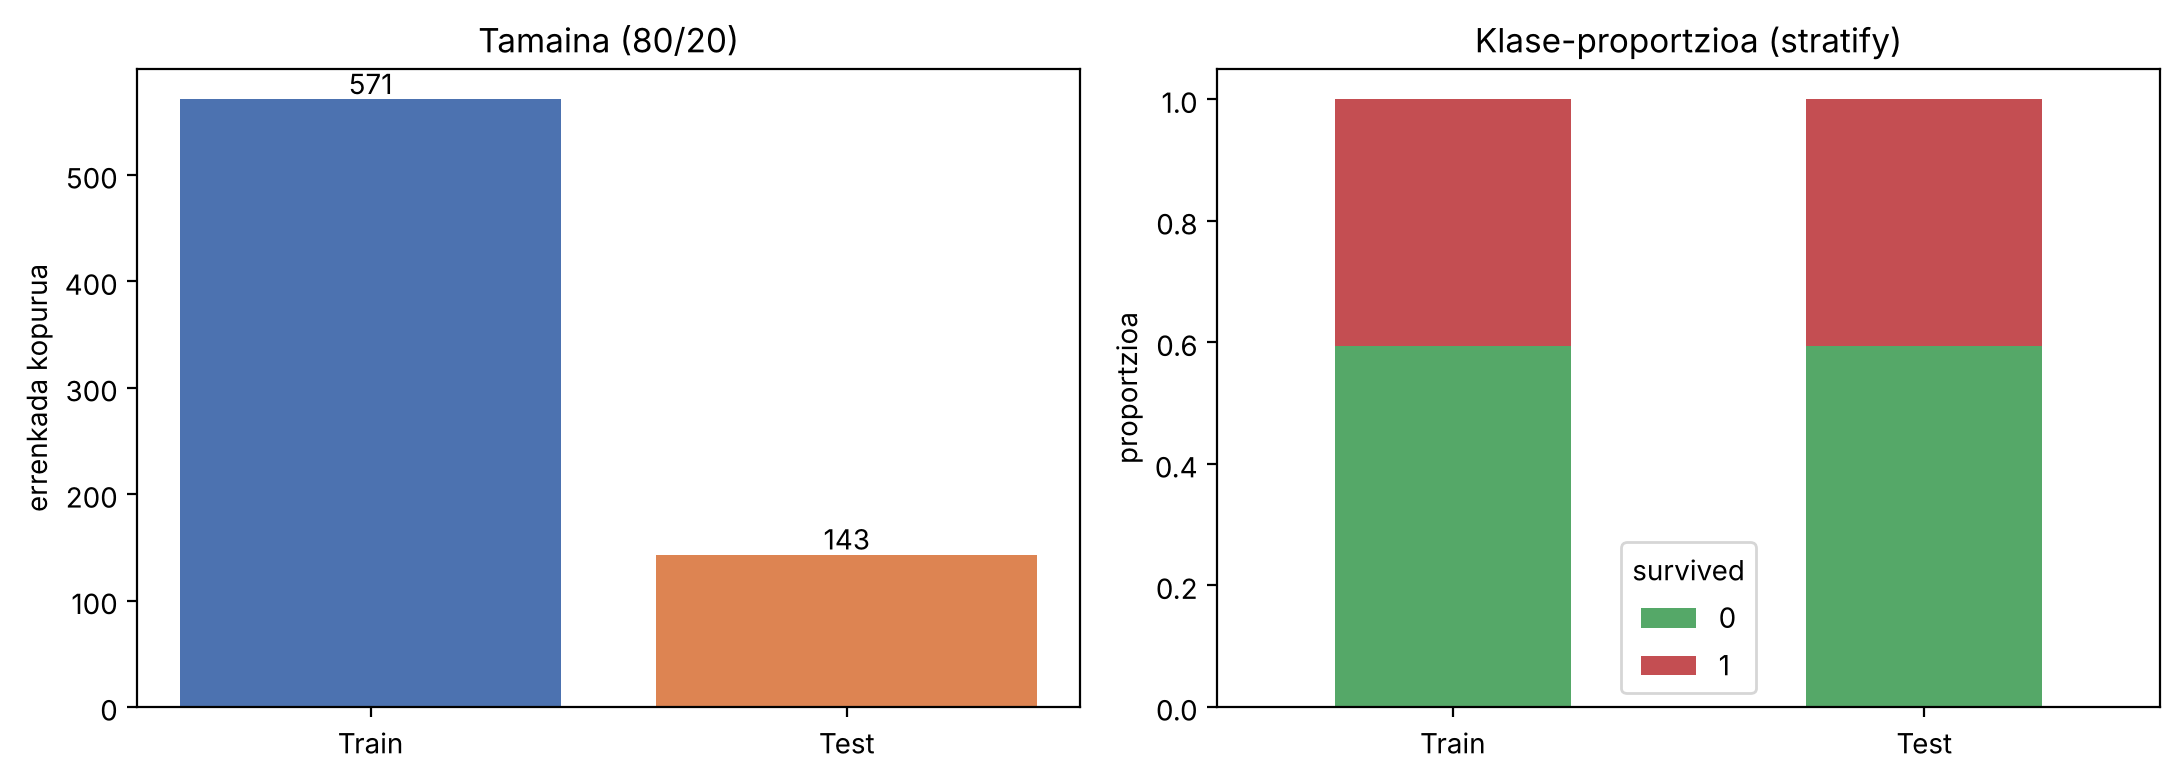

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
# Ezkerra: tamaina
ax[0].bar(['Train', 'Test'], [len(y_train), len(y_test)], color=['#4C72B0',
'#DD8452'])
ax[0].set_title('Tamaina (80/20)'); ax[0].set_ylabel('errenkada kopurua')
for i, v in enumerate([len(y_train), len(y_test)]): ax[0].text(i, v+5, str(v),
ha='center')

prop.T.plot(kind='bar', stacked=True, ax=ax[1], color=['#55A868', '#C44E52'])
ax[1].set_title('Klase-proportzioa (stratify)'); ax[1].set_ylabel('proportzioa')
ax[1].legend(title='survived'); ax[1].set_xticklabels(['Train','Test'],
rotation=0)
plt.tight_layout(); plt.show()

In [5]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
num = df[['age','fare']].fillna(df[['age','fare']].median())
# Hiru eskalatzaileak konparatu fare zutabean
for izena, sc in [('Standard', StandardScaler()), ('MinMax', MinMaxScaler()), ('Robust', RobustScaler())]:
    esk = sc.fit_transform(num)
    print(f'{izena:9s} fare -> batez {esk[:,1].mean():+.2f} | min {esk[:,1].min():.2f} | max {esk[:,1].max():.2f}')

Standard  fare -> batez +0.00 | min -0.65 | max 9.67
MinMax    fare -> batez +0.06 | min 0.00 | max 1.00
Robust    fare -> batez +0.77 | min -0.63 | max 21.56


In [6]:
num_cols = ['age', 'fare', 'pclass']
sc = StandardScaler()
X_train_num = sc.fit_transform(X_train[num_cols]) # fit + transform (train)
X_test_num = sc.transform(X_test[num_cols]) # transform SOILIK
print('Train batez (eskalatuta ~0):', X_train_num.mean(axis=0).round(2))
print('Test batez (train-en estatistikekin):', X_test_num.mean(axis=0).round(2))

Train batez (eskalatuta ~0): [-0. -0.  0.]
Test batez (train-en estatistikekin): [ 0.13  0.1  -0.02]


**• Zertarako egiten da stratify=y?**

Train eta test multzoetan **klaseen proportzio bera** mantentzeko. Hemen bietan %59.4 hil / %40.6 bizirik dago (`prop` taula). Horrela test-a train-en adierazgarria da eta ebaluazioa ez da zortearen menpe geratzen (bereziki klase desorekatuetan garrantzitsua).

**• Zein eskalatzailea erabakiko zenuke?**

`fare`-rentzat **RobustScaler**: mediana eta IQR erabiltzen ditu, eta outlierrek ez dute eskalatzea hondatzen. StandardScaler-ek media eta std erabiltzen ditu (outlierrek puztuak) eta MinMax-ek max-a (512), beraz balio gehienak 0 ondoan pilatzen dira (MinMax-en max = 1 baina batezbestekoa 0.06 baino ez). Robust-ekin outlierrak handiak geratzen dira (max 21.56), baina datuen gehiengoa ondo eskalatuta dago. `age`-rentzat (outlier gutxi) StandardScaler nahikoa da.

**• Zergatik eskalatzen da train multzoa?**

**Data leakage** saihesteko. Eskalatzaileak parametroak ikasten ditu datuetatik (media, std, min, max...). Test-arekin ere `fit` egingo bagenu, modeloak test-eko informazioa "ikusiko" luke entrenatu aurretik, eta ebaluazioa baikorregia izango litzateke. Horregatik: `fit_transform(train)` → parametroak train-etik ikasi; `transform(test)` → parametro BERAK aplikatu. Horregatik test-aren batezbestekoa ez da zehazki 0 (0.13, 0.1, -0.02), eta hori zuzena da.